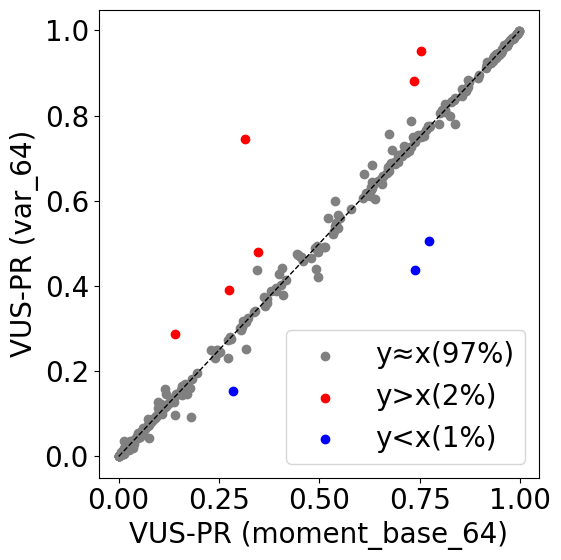

In [6]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

# Read VUS-PR scores, you may change path_x and path_y to paths where your reproduction results are located
path_x = f'../results/tsfms/moment_base_64.csv'
path_y = f'../results/baselines/var_64.csv'

# Use the file name (without extension) as label for the plot
label_x = Path(path_x).stem
label_y = Path(path_y).stem

x = pd.read_csv(path_x)['VUS-PR'].to_numpy()
y = pd.read_csv(path_y)['VUS-PR'].to_numpy()

# Uncomment the following lines to remove time series that we found to be with problematic labeling (See Appendix H in the paper for details). 
# to_remove = list(range(245, 262))
# to_remove += [43, 45, 47, 48, 68, 74, 212, 221,228]
# to_remove += list (range(23))
# x = np.delete(x, to_remove)
# y = np.delete(y, to_remove)

# One series in the TSB-AD-U evaluation set is shorter than 1024, which results in a None value for the metric when window size is 1024.
# We remove this value for the comparison.
mask = ~np.isnan(y)
x = x[mask]
y = y[mask]

# Define deviation threshold for visualization
threshold = 0.1
deviation_mask1 = (y - x) > threshold
deviation_mask2 = (x - y) > threshold
close_mask = ~(deviation_mask1 | deviation_mask2)

fig = plt.figure(figsize=(6, 6))

# set all fonts to 20
plt.rcParams.update({'font.size': 20})

# Plot points near y = x
plt.scatter(x[close_mask], y[close_mask], color='gray', label=f'y≈x({close_mask.sum()/x.size:.0%})')

# Plot deviating points
plt.scatter(x[deviation_mask1], y[deviation_mask1], color='red', label=f'y>x({deviation_mask1.sum()/x.size:.0%})')
plt.scatter(x[deviation_mask2], y[deviation_mask2], color='blue', label=f'y<x({deviation_mask2.sum()/x.size:.0%})')

# Plot y = x reference line
lims = [min(x.min(), y.min()), max(x.max(), y.max())]
plt.plot(lims, lims, 'k--', linewidth=1)

plt.xlabel(f'VUS-PR ({label_x})')
plt.ylabel(f'VUS-PR ({label_y})')
plt.legend()
plt.tight_layout()
plt.show()